# Lab 3 — Thực hành Naive Bayes

Nguyễn Đình Huy — MSSV: 2474802010140.

Mỗi mục bên dưới có một cell code, gồm thiết lập đường dẫn, mã tính toán và hình minh họa (nếu có). Chọn **Run All** để chạy toàn bộ. Trên Colab, tải hai CSV vào Files hoặc thư mục `data/`.

## Thực hành 1 — Tính định lý Bayes bằng tay
Theo mục 2.4, tương ứng `d1_bayes_tay.py` trong tài liệu. Các con số xét nghiệm chỉ là ví dụ toán học trong bài.

In [1]:
from pathlib import Path

# Chạy từ thư mục bài, code/, hoặc thư mục chứa CSV đã tải lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "tin_nhan.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)


# Mã thực hành / bài tập
def bayes(tien_nghiem, kha_nang, kha_nang_nguoc):
    """Trả về xác suất hậu nghiệm P(A | B)."""
    tu_so = kha_nang * tien_nghiem
    mau_so = tu_so + kha_nang_nguoc * (1 - tien_nghiem)
    return tu_so / mau_so

print("Vi du 1: xet nghiem benh")
print("  Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.")
p = bayes(tien_nghiem=0.01, kha_nang=0.99, kha_nang_nguoc=0.01)
print(f"  Duong tinh thi kha nang co benh that = {p:.4f}")
print()

# Giữ nguyên chất lượng xét nghiệm, chỉ đổi tỷ lệ mắc bệnh.
print("Cung xet nghiem do, doi ty le mac benh:")
print("  Ty le mac benh    Hau nghiem khi duong tinh")
for ty_le in [0.001, 0.01, 0.05, 0.10, 0.50]:
    print(f"    {ty_le:6.3f}             {bayes(ty_le, 0.99, 0.01):.4f}")
print()

print("Vi du 2: hai day chuyen san xuat")
print("  Day A lam 80 phan tram san pham, ty le loi 1 phan tram.")
print("  Day B lam 20 phan tram san pham, ty le loi 5 phan tram.")
# Ở đây A trong công thức nghĩa là sản phẩm đến từ dây B.
p_b = bayes(tien_nghiem=0.20, kha_nang=0.05, kha_nang_nguoc=0.01)
print(f"  Nhat duoc san pham loi, kha nang no tu day B = {p_b:.4f}")
print()

print("Kiem lai bang cach dem tren 1000 san pham:")
loi_a = 800 * 0.01
loi_b = 200 * 0.05
print(f"  Day A: 800 san pham, {loi_a:.0f} cai loi")
print(f"  Day B: 200 san pham, {loi_b:.0f} cai loi")
tong_loi = loi_a + loi_b
print(f"  Ty le tu day B = {loi_b} / {tong_loi} = {loi_b / tong_loi:.4f}")

Vi du 1: xet nghiem benh
  Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.
  Duong tinh thi kha nang co benh that = 0.5000

Cung xet nghiem do, doi ty le mac benh:
  Ty le mac benh    Hau nghiem khi duong tinh
     0.001             0.0902
     0.010             0.5000
     0.050             0.8390
     0.100             0.9167
     0.500             0.9900

Vi du 2: hai day chuyen san xuat
  Day A lam 80 phan tram san pham, ty le loi 1 phan tram.
  Day B lam 20 phan tram san pham, ty le loi 5 phan tram.
  Nhat duoc san pham loi, kha nang no tu day B = 0.5556

Kiem lai bang cach dem tren 1000 san pham:
  Day A: 800 san pham, 8 cai loi
  Day B: 200 san pham, 10 cai loi
  Ty le tu day B = 10.0 / 18.0 = 0.5556


## Thực hành 2 — Biến văn bản thành túi từ
Theo mục 3.3, giữ `token_pattern=r"(?u)\S+"` để tách từ bằng khoảng trắng, kể cả từ một ký tự.

In [2]:
from pathlib import Path

# Chạy từ thư mục bài, code/, hoặc thư mục chứa CSV đã tải lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "tin_nhan.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)


# Mã thực hành / bài tập
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

df = pd.read_csv(tep_du_lieu("tin_nhan.csv"))
print("Kich thuoc bang:", df.shape)
print()
print("So tin theo nhan (1 la rac, 0 la thuong):")
print(df["la_rac"].value_counts())
print()
print("Ty le tin rac:", round(df["la_rac"].mean(), 4))
print()

print("Ba tin nhan dau tien:")
for i in range(3):
    print(f"  [{df.la_rac[i]}] {df.noi_dung[i]}")
print()

vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])
print("Kich thuoc bang dem tu:", X.shape)
print("So tu trong tu dien:", len(vec.vocabulary_))
print()

# Đếm tổng số lần xuất hiện của từng từ, tách theo hai lớp.
dem = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())
dem["la_rac"] = df["la_rac"]
tong = dem.groupby("la_rac").sum().T
tong.columns = ["thuong", "rac"]
print("Muoi tu xuat hien nhieu nhat trong tin rac:")
print(tong.sort_values("rac", ascending=False).head(10))
print()
print("Muoi tu xuat hien nhieu nhat trong tin thuong:")
print(tong.sort_values("thuong", ascending=False).head(10))

Kich thuoc bang: (300, 2)

So tin theo nhan (1 la rac, 0 la thuong):
la_rac
0    180
1    120
Name: count, dtype: int64

Ty le tin rac: 0.4

Ba tin nhan dau tien:
  [0] cáo gửi cáo thầy nhóm cáo gửi có cho
  [1] miễn giảm ngay hạn miễn tay nhé thưởng cho nhanh
  [0] cho bạn mai gửi nhóm bài chiều

Kich thuoc bang dem tu: (300, 40)
So tu trong tu dien: 40

Muoi tu xuat hien nhieu nhat trong tin rac:
       thuong  rac
tay         3   48
ngay        4   47
nhanh       9   44
chót        6   43
giảm        6   42
lúc        39   42
quà         8   41
click       5   40
phí         6   40
miễn        4   39

Muoi tu xuat hien nhieu nhat trong tin thuong:
       thuong  rac
thầy       74    7
bài        73    4
cáo        72    8
chiều      68    8
ạ          65    7
tài        64   11
tập        63    6
gửi        61   10
lớp        60    2
nhóm       58    7


## Thực hành 3 — Huấn luyện bộ lọc thư rác
Theo mục 4.2: `alpha=1.0`, `test_size=0.25`, `random_state=17`, `stratify=y`. Giữ nguyên cả ba câu thử không dấu trong mã mẫu.

So tin de hoc     : 225
So tin de kiem tra: 75

Ma tran nham lan
  TN = 45   thu thuong duoc giu dung
  FP =  0   thu thuong bi xoa nham
  FN =  4   thu rac lot luoi
  TP = 26   thu rac bi chan dung

Accuracy  = 0.9467
Precision = 1.0000
Recall    = 0.8667

Thu tren ba tin nhan tu go:
  [RAC   ] p = 0.9992  <- trung thuong khuyen mai nhanh tay click ngay
  [thuong] p = 0.0983  <- hop nhom bao cao chieu mai phong 305
  [thuong] p = 0.0719  <- ban gui giup em tai lieu bai tap nhe


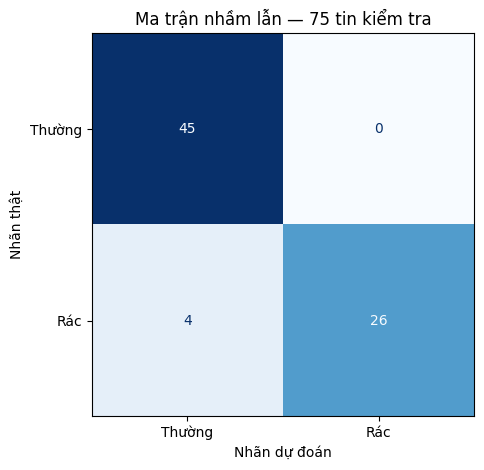

In [3]:
from pathlib import Path

# Chạy từ thư mục bài, code/, hoặc thư mục chứa CSV đã tải lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "tin_nhan.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)


# Mã thực hành / bài tập
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv(tep_du_lieu("tin_nhan.csv"))
# Giữ thứ tự vector hóa rồi chia như mã d3 của tài liệu để đối chiếu.
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])
y = df["la_rac"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

print("So tin de hoc     :", X_train.shape[0])
print("So tin de kiem tra:", X_test.shape[0])
print()
mo_hinh = MultinomialNB(alpha=1.0)
mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma tran nham lan")
print(f"  TN = {tn:2d}   thu thuong duoc giu dung")
print(f"  FP = {fp:2d}   thu thuong bi xoa nham")
print(f"  FN = {fn:2d}   thu rac lot luoi")
print(f"  TP = {tp:2d}   thu rac bi chan dung")
print()
print(f"Accuracy  = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall    = {recall_score(y_test, y_pred):.4f}")
print()

tin_moi = [
    "trung thuong khuyen mai nhanh tay click ngay",
    "hop nhom bao cao chieu mai phong 305",
    "ban gui giup em tai lieu bai tap nhe",
]
X_moi = vec.transform(tin_moi)
p_rac = mo_hinh.predict_proba(X_moi)[:, 1]
print("Thu tren ba tin nhan tu go:")
for tin, p in zip(tin_moi, p_rac):
    nhan = "RAC" if p >= 0.5 else "thuong"
    print(f"  [{nhan:6s}] p = {p:.4f}  <- {tin}")

# Hình minh họa bổ sung, lưu vào figures/
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Thường", "Rác"], cmap="Blues", colorbar=False
)
plt.title("Ma trận nhầm lẫn — 75 tin kiểm tra")
plt.xlabel("Nhãn dự đoán")
plt.ylabel("Nhãn thật")
plt.tight_layout()
plt.savefig(thu_muc_hinh / "d3_ma_tran_nham_lan.png", dpi=150)
plt.show()

## Thực hành 4 — Tự cài Naive Bayes và làm trơn Laplace
Theo mục 5.3: kho sáu tin nhắn, điểm bằng tích xác suất, so sánh alpha bằng 0 và 1.

Tu dien co 18 tu:
  bai chieu click gia giam gui hop khuyen lieu
  mai ngay nhom nop tai tap thay thuong trung

So lan xuat hien cua tung tu
  tu             rac  thuong
  bai              0       1
  chieu            0       1
  click            1       0
  gia              1       0
  giam             1       0
  gui              0       1
  hop              0       1
  khuyen           1       0
  lieu             0       1
  mai              1       2
  ngay             1       0
  nhom             0       2
  nop              0       1
  tai              0       1
  tap              0       1
  thay             0       1
  thuong           2       0
  trung            2       0

Tin nhan thu: "trung thuong bai tap"
Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.

alpha = 0.0
  diem lop rac    = 0.0000000000
  diem lop thuong = 0.0000000000
  ket luan        = thuong

alpha = 1.0
  diem lop rac    = 0.0000073212
  diem lop thuong = 0.0000021656
  ket luan        = rac


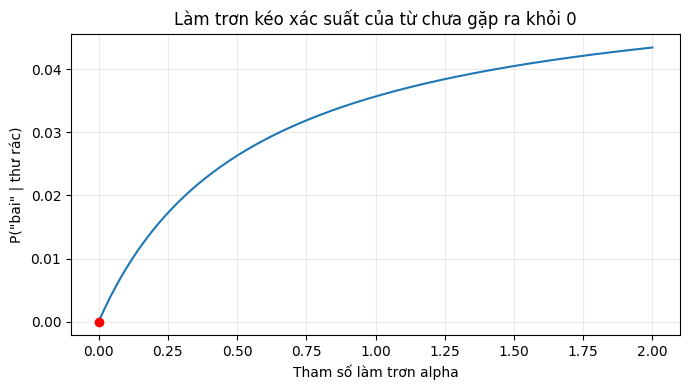

In [4]:
from pathlib import Path

# Chạy từ thư mục bài, code/, hoặc thư mục chứa CSV đã tải lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "tin_nhan.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)


# Mã thực hành / bài tập
from collections import Counter

kho = [
    ("trung thuong ngay", 1),
    ("khuyen mai giam gia", 1),
    ("trung thuong click", 1),
    ("hop nhom chieu mai", 0),
    ("bai tap nhom nop mai", 0),
    ("thay gui tai lieu", 0),
]
tu_dien = sorted({t for cau, _ in kho for t in cau.split()})
V = len(tu_dien)
print(f"Tu dien co {V} tu:")
for i in range(0, V, 9):
    print("  " + " ".join(tu_dien[i:i + 9]))
print()

dem = {0: Counter(), 1: Counter()}
tong = {0: 0, 1: 0}
for cau, nhan in kho:
    for t in cau.split():
        dem[nhan][t] += 1
        tong[nhan] += 1

print("So lan xuat hien cua tung tu")
print(f"  {'tu':12s} {'rac':>5s} {'thuong':>7s}")
for t in tu_dien:
    print(f"  {t:12s} {dem[1][t]:5d} {dem[0][t]:7d}")
print()

def xac_suat(tu, nhan, alpha):
    """P(từ | nhãn) có làm trơn Laplace với hệ số alpha."""
    return (dem[nhan][tu] + alpha) / (tong[nhan] + alpha * V)

def diem(cau, nhan, alpha):
    """Tích của xác suất tiên nghiệm và các xác suất từ."""
    p = 0.5  # Hai lớp cân bằng nên tiên nghiệm bằng nhau.
    for t in cau.split():
        if t in tu_dien:
            p *= xac_suat(t, nhan, alpha)
    return p

cau_thu = "trung thuong bai tap"
print(f'Tin nhan thu: "{cau_thu}"')
print("Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.")
print()
for alpha in [0.0, 1.0]:
    d_rac = diem(cau_thu, 1, alpha)
    d_thuong = diem(cau_thu, 0, alpha)
    ket = "rac" if d_rac > d_thuong else "thuong"
    print(f"alpha = {alpha}")
    print(f"  diem lop rac    = {d_rac:.10f}")
    print(f"  diem lop thuong = {d_thuong:.10f}")
    print(f"  ket luan        = {ket}")
    print()
print("Khong lam tron, CA HAI diem deu bang 0 nen mo hinh te liet.")
print("Lop rac bang 0 vi tu 'bai' chua tung xuat hien o lop rac.")
print("Lop thuong bang 0 vi tu 'trung' chua tung xuat hien o lop thuong.")
print("Co lam tron, diem lop rac lon hon va mo hinh ket luan dung.")

# Hình minh họa bổ sung, lưu vào figures/
import numpy as np
import matplotlib.pyplot as plt

cac_alpha = np.linspace(0, 2, 201)
plt.figure(figsize=(7, 4))
plt.plot(cac_alpha, [xac_suat("bai", 1, a) for a in cac_alpha])
plt.scatter([0], [0], color="red", zorder=3)
plt.title("Làm trơn kéo xác suất của từ chưa gặp ra khỏi 0")
plt.xlabel("Tham số làm trơn alpha")
plt.ylabel('P("bai" | thư rác)')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "d4_lam_tron_laplace.png", dpi=150)
plt.show()

## Thực hành 5 — GaussianNB cho số liệu liên tục
Theo mục 6.2, so sánh GaussianNB và Logistic Regression trên cùng tập học/kiểm tra của dữ liệu sinh viên.

Naive Bayes    : accuracy = 0.9000
Hoi quy logistic: accuracy = 0.9000

Nhung gi Naive Bayes hoc duoc
                       gio_on   diem_giua_ky
  Lop 0 (rot) trung binh       8.18           3.99
              do lech         5.29           1.92
  Lop 1 (qua) trung binh      20.03           6.70
              do lech         5.81           1.50

Ty le tung lop trong tap hoc: 0.4111, 0.5889

Du doan cho bon ban moi:
    gio on   diem GK   P(qua mon)
         5       4.0       0.0137
        13       6.0       0.6550
        20       7.0       0.9855
        28       9.0       0.9999


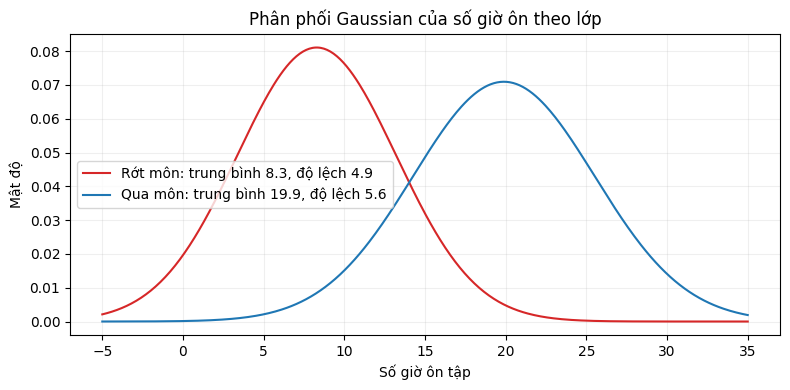

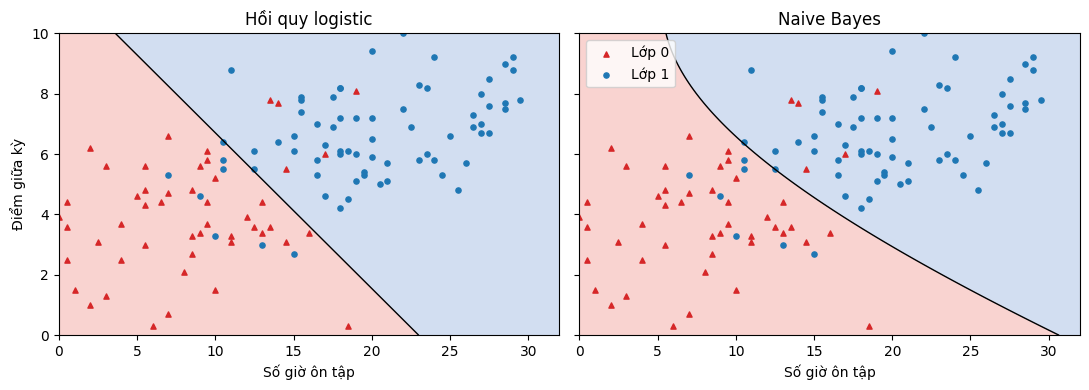

In [5]:
from pathlib import Path

# Chạy từ thư mục bài, code/, hoặc thư mục chứa CSV đã tải lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "tin_nhan.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)


# Mã thực hành / bài tập
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB

df = pd.read_csv(tep_du_lieu("sinh_vien.csv"))
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

from sklearn.linear_model import LogisticRegression

for ten, mo_hinh in [("Naive Bayes    ", GaussianNB()),
                    ("Hoi quy logistic", LogisticRegression())]:
    mo_hinh.fit(X_train, y_train)
    acc = accuracy_score(y_test, mo_hinh.predict(X_test))
    print(f"{ten}: accuracy = {acc:.4f}")
print()

gnb = GaussianNB().fit(X_train, y_train)
# theta_ là trung bình, var_ là phương sai, mỗi dòng một lớp.
print("Nhung gi Naive Bayes hoc duoc")
print(f"  {'':16s} {'gio_on':>10s} {'diem_giua_ky':>14s}")
for i, ten_lop in enumerate(["Lop 0 (rot)", "Lop 1 (qua)"]):
    tb = gnb.theta_[i]
    dl = gnb.var_[i] ** 0.5
    print(f"  {ten_lop} trung binh {tb[0]:10.2f} {tb[1]:14.2f}")
    print(f"  {'':11s} do lech   {dl[0]:10.2f} {dl[1]:14.2f}")
print()
ty_le = ", ".join(f"{float(v):.4f}" for v in gnb.class_prior_)
print(f"Ty le tung lop trong tap hoc: {ty_le}")
print()

ban_moi = pd.DataFrame({"gio_on": [5, 13, 20, 28],
                       "diem_giua_ky": [4.0, 6.0, 7.0, 9.0]})
p = gnb.predict_proba(ban_moi)[:, 1]
print("Du doan cho bon ban moi:")
print(f"  {'gio on':>8s} {'diem GK':>9s} {'P(qua mon)':>12s}")
for (_, r), pi in zip(ban_moi.iterrows(), p):
    print(f"  {r.gio_on:8.0f} {r.diem_giua_ky:9.1f} {pi:12.4f}")

# Hình minh họa bổ sung, lưu vào figures/
import numpy as np
import matplotlib.pyplot as plt

# Hình chuông mô tả toàn bộ dữ liệu, như hình minh họa mục 6.1.
gio = np.linspace(-5, 35, 400)
plt.figure(figsize=(8, 4))
for nhan, ten, mau in [(0, "Rớt môn", "tab:red"), (1, "Qua môn", "tab:blue")]:
    mau_gio = df.loc[df.qua_mon == nhan, "gio_on"]
    tb, dl = mau_gio.mean(), mau_gio.std(ddof=0)
    mat_do = np.exp(-0.5 * ((gio - tb) / dl) ** 2) / (dl * np.sqrt(2 * np.pi))
    plt.plot(gio, mat_do, color=mau, label=f"{ten}: trung bình {tb:.1f}, độ lệch {dl:.1f}")
plt.title("Phân phối Gaussian của số giờ ôn theo lớp")
plt.xlabel("Số giờ ôn tập")
plt.ylabel("Mật độ")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "d5_duong_chuong.png", dpi=150)
plt.show()

gio_grid, diem_grid = np.meshgrid(np.linspace(0, 32, 200), np.linspace(0, 10, 160))
luoi = pd.DataFrame({"gio_on": gio_grid.ravel(), "diem_giua_ky": diem_grid.ravel()})
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, (ten, model) in zip(axes, [("Hồi quy logistic", LogisticRegression()), ("Naive Bayes", GaussianNB())]):
    model.fit(X_train, y_train)
    prob = model.predict_proba(luoi)[:, 1].reshape(gio_grid.shape)
    ax.contourf(gio_grid, diem_grid, prob, levels=[0, 0.5, 1], colors=["#f5b7b1", "#b5c9e8"], alpha=0.6)
    ax.contour(gio_grid, diem_grid, prob, levels=[0.5], colors="black", linewidths=1)
    for nhan, mau, marker in [(0, "tab:red", "^"), (1, "tab:blue", "o")]:
        nhom = df[df.qua_mon == nhan]
        ax.scatter(nhom.gio_on, nhom.diem_giua_ky, s=14, c=mau, marker=marker, label=f"Lớp {nhan}")
    ax.set_title(ten)
    ax.set_xlabel("Số giờ ôn tập")
axes[0].set_ylabel("Điểm giữa kỳ")
axes[1].legend()
fig.tight_layout()
fig.savefig(thu_muc_hinh / "d5_bien_quyet_dinh.png", dpi=150)
plt.show()